<center><h1> Full RC Time Series Diffusion Models <h1><center>

In [1]:
%load_ext autoreload
%autoreload 2

# Table of Contents
1. [Intro](#Introduction)
2. [Data](#Data)
3. [Model Specifications](#Model-Specifications)
4. [Training](#Training)
5. [Testing](#Testing)

# Introduction

In [2]:
import torch 
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt 

In [3]:
# Select cuda if available 

# Data

In [4]:
from rcdiff.data.rv import RVSP500

rvSP500 = RVSP500()
(dates_train, RV_train), (dates_test, RV_test) = rvSP500.get_realized_variance_data(len_train=2000, standardize=False)

# Model Specifications

In [5]:
from rcdiff.diff import DDPM, BaseScheduler

K = 100

scheduler = BaseScheduler(K = K)
ddpm = DDPM(scheduler=scheduler)

In [6]:
from rcdiff import ESN 
from rcdiff import RandomWeight, ParametersESN

R = 25 
T, N = RV_train.shape

A = RandomWeight(dist="normal", sparsity=0, norm_type="spectral_radius")
C = RandomWeight(dist="uniform", sparsity=0, norm_type="l2")
zeta = RandomWeight(dist="uniform", sparsity=0, norm_type="euclidean")

esnParams = ParametersESN(A_RW = A, 
                 C_RW = C,
                 zeta_RW = zeta,
                 leak_rate = 0.3, 
                 rho = 0.9, 
                 gamma = 0.1,
                 omega = 0) 

esn = ESN(in_dim = N, 
          reservoir_size= R, 
          params=esnParams
          )

In [19]:
from rcdiff import RWDenoisingNetwork, ParametersRWDN

H = 25

A_k = RandomWeight("uniform", sparsity=0.2, norm_type="l2")
b_k = RandomWeight("uniform", sparsity=0.2, norm_type="euclidean")

rwdnParams = ParametersRWDN(A_k = A_k,
               b_k = b_k,
               gamma = 0.5, 
               omega = 0.3)

rwdn = RWDenoisingNetwork(in_dim = N, 
                          hidden_size = H, 
                          reservoir_size = R,
                          params = rwdnParams, 
                          K = K)

In [20]:
from rcdiff.models.config import TrainConfig

train_spec = TrainConfig(t0 = 100,
                        seed = 1234,
                        device = "cpu")  

In [21]:
from rcdiff import RCDiff 

rcdiffusion = RCDiff(diff = ddpm, esn = esn, denoiser = rwdn, spec = train_spec)

# Training

In [22]:
df_loss, time = rcdiffusion.fit(x = RV_train, c = None)

100


100%|██████████| 100/100 [00:00<00:00, 140.23it/s]


Training complete Time: 0.72s
100


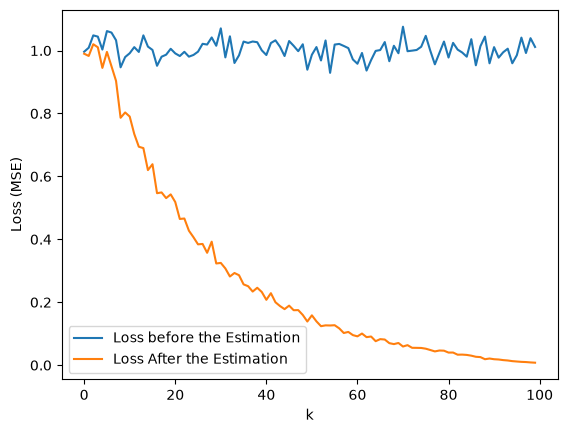

In [23]:
plt.plot(df_loss['k'], df_loss['LossBefore'], label = 'Loss before the Estimation')
plt.plot(df_loss['k'], df_loss['LossAfter'], label = 'Loss After the Estimation')
plt.ylabel('Loss (MSE)')
plt.xlabel('k')
plt.legend()
plt.show()

# Testing

A one step ahead can be performed by: 

In [41]:
x_hat, full_reverse = rcdiffusion.conditional_distribution(x = RV_train, c = None, n_samples=50)
print('Actual obs', round(RV_test[0].item(),2))
print('Predicted obs', round(x_hat[0].mean().item(), 2))

Actual obs 0.67
Predicted obs 0.52


In [ ]:
obs = 1000 # len(RV_test) # 1000 
test = RV_test[:obs]

forecast = rcdiffusion.one_step_ahead_forecast(x_train = RV_train, x_test = test)

 27%|██▋       | 270/1000 [00:08<00:21, 34.06it/s]

In [ ]:
import torch.nn.functional as F 

F_m = forecast.mean(dim = 1)

F.mse_loss(F_m, test) # should be around 3.6 to be good

tensor(21.4074)

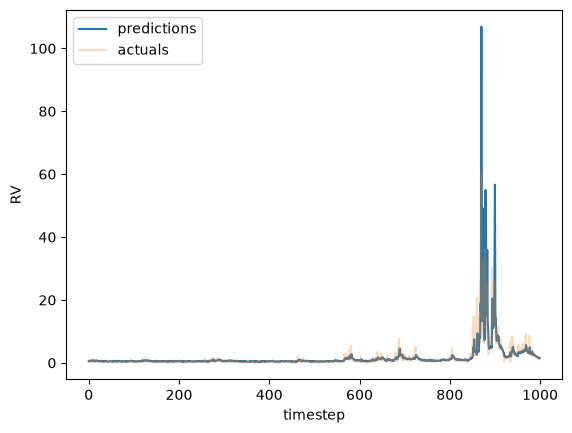

In [ ]:
plt.plot(F_m.detach().numpy(), label = 'predictions')
plt.plot(test.detach().numpy(), label = 'actuals', alpha = 0.3)
plt.ylabel('RV')
plt.xlabel('timestep')
plt.legend()
plt.show()